<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/07_neural_duration_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 · Neural duration predictor (BiLSTM)
**Goal:** a small neural model that reads the **whole utterance** (not just a ±2 window) and predicts one duration per phone, like the duration predictor in FastSpeech-style TTS. It is the bridge to Phase 2 (same inputs, same shapes).

**Architecture**
`embeddings(phone, stress, class, punctuation) + small linear layer on numeric/flag features` -> concatenate -> **2-layer bidirectional LSTM** -> MLP -> `log(duration in frames)`.
- Why a BiLSTM? Duration depends on both left and right context (e.g. phrase-final lengthening needs to know what comes *after*).
- Loss: **masked MSE on log duration** (padding must not count). Log space because durations are right-skewed (notebook 04).
- Early stopping on val MAE (in frames), best weights restored; test is scored once at the end.

**Use a GPU:** Runtime -> Change runtime type -> T4. **Reads:** `features.csv.gz`. **Writes:** `results/07_*`, `results/preds_bilstm.csv`, checkpoint `results/duration_bilstm.pt`.

In [1]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [2]:
# ---- Write shared module: duration metrics
import os, importlib
_src = r'''"""Duration metrics. Durations are in mel frames (hop 256 @ 22,050 Hz = 11.61 ms per frame)."""
import numpy as np

FRAME_MS = 256 / 22050 * 1000


def summarize(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = p - y
    ss_res, ss_tot = (err ** 2).sum(), ((y - y.mean()) ** 2).sum()
    return {
        'mae_frames': float(np.abs(err).mean()),
        'mae_ms': float(np.abs(err).mean() * FRAME_MS),
        'rmse_frames': float(np.sqrt((err ** 2).mean())),
        'rmse_ms': float(np.sqrt((err ** 2).mean()) * FRAME_MS),
        'r2': float(1 - ss_res / ss_tot),
        'bias_frames': float(err.mean()),
        'n': int(len(y)),
    }
'''
_p = os.path.join(PROJECT_ROOT, "src/evaluation/metrics.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/evaluation/metrics.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/evaluation/metrics.py


In [3]:
import numpy as np, pandas as pd, torch, torch.nn as nn, time, random
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from src.features.phones import PHONE2ID, CLASS2ID, CLASS_LIST
from src.evaluation.metrics import summarize
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('device:', dev)
feat = pd.read_csv(os.path.join(PROCESSED, 'features.csv.gz'), keep_default_na=False, na_values=[''])
feat = feat.sort_values(['utt_id', 'seq_idx']).reset_index(drop=True)

device: cuda


## Step 1: Turn the table into sequences
Each utterance becomes a sequence of phones. We keep `row_id` so predictions map back to the feature table (needed for notebook 08).

In [4]:
PUNCT = {'n': 0, 'c': 1, 'p': 2}
FLAGS = ['is_word_first', 'is_word_last', 'pause_after', 'pause_before', 'is_utt_first', 'is_utt_final', 'is_vowel']
feat['ph_id'] = feat['base'].map(PHONE2ID); assert feat['ph_id'].notna().all()
feat['st_id'] = feat['stress_c'].astype(int) + 1                      # -1..2 -> 0..3
feat['cl_id'] = feat['cls'].map(CLASS2ID)
feat['pu_id'] = feat['word_punct'].map(PUNCT).fillna(0).astype(int)
feat['num1'] = feat['rel_pos_utt']; feat['num2'] = feat['rel_pos_in_word']; feat['num3'] = feat['word_len'] / 10; feat['num4'] = feat['pos_in_word'] / 10
NUMF = FLAGS + ['num1', 'num2', 'num3', 'num4']                       # 11 numeric inputs

def make_split(name):
    out = []
    for uid, d in feat[feat.split == name].groupby('utt_id', sort=False):
        out.append(dict(
            ph=torch.tensor(d.ph_id.values), st=torch.tensor(d.st_id.values), cl=torch.tensor(d.cl_id.values), pu=torch.tensor(d.pu_id.values),
            x=torch.tensor(d[NUMF].values, dtype=torch.float32), y=torch.tensor(d.log_dur.values, dtype=torch.float32), row=d.row_id.values))
    return out
data = {s: make_split(s) for s in ('train', 'val', 'test')}
print({k: len(v) for k, v in data.items()}, 'utterances | numeric inputs:', len(NUMF))

def collate(b):
    L = torch.tensor([len(i['ph']) for i in b])
    pad = lambda k, v=0: pad_sequence([i[k] for i in b], batch_first=True, padding_value=v)
    return pad('ph'), pad('st'), pad('cl'), pad('pu'), pad('x', 0.0), pad('y', 0.0), L
def loader(split, bs, shuffle):
    return torch.utils.data.DataLoader(data[split], batch_size=bs, shuffle=shuffle, collate_fn=collate)

{'train': 10283, 'val': 581, 'test': 552} utterances | numeric inputs: 11


## Step 2: The model

In [5]:
class DurNet(nn.Module):
    def __init__(s, n_ph, n_num, hid=128, layers=2, drop=0.2):
        super().__init__()
        s.ph = nn.Embedding(n_ph, 64, padding_idx=0); s.st = nn.Embedding(4, 8); s.cl = nn.Embedding(len(CLASS_LIST), 8); s.pu = nn.Embedding(3, 4)
        s.num = nn.Linear(n_num, 16)
        s.rnn = nn.LSTM(64 + 8 + 8 + 4 + 16, hid, layers, batch_first=True, bidirectional=True, dropout=drop)
        s.out = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * hid, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(s, ph, st, cl, pu, x, L):
        h = torch.cat([s.ph(ph), s.st(st), s.cl(cl), s.pu(pu), torch.relu(s.num(x))], -1)
        packed = pack_padded_sequence(h, L.cpu(), batch_first=True, enforce_sorted=False)
        o, _ = s.rnn(packed); o, _ = pad_packed_sequence(o, batch_first=True, total_length=ph.shape[1])
        return s.out(o).squeeze(-1)                                   # predicted log-duration per phone

model = DurNet(len(PHONE2ID), len(NUMF)).to(dev)
print('trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

trainable parameters: 650293


## Step 3: Training loop
Gradient clipping (1.0) keeps LSTM training stable; `ReduceLROnPlateau` lowers the learning rate when val stops improving; training stops after `PATIENCE` epochs without improvement.

In [6]:
CFG = dict(batch=64, lr=2e-3, epochs=30, patience=5, hid=128, layers=2, drop=0.2, seed=SEED)
def run_eval(split):
    model.eval(); P, Y, R = [], [], []
    with torch.no_grad():
        for bi, b in enumerate(loader(split, 128, False)):
            ph, st, cl, pu, x, y, L = [t.to(dev) for t in b]
            p = model(ph, st, cl, pu, x, L).cpu(); m = (torch.arange(ph.shape[1])[None, :] < L.cpu()[:, None])
            P.append(p[m].numpy()); Y.append(y.cpu()[m].numpy())
    rows = np.concatenate([i['row'] for i in data[split]])
    return rows, np.exp(np.concatenate(Y)), np.exp(np.concatenate(P))

opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
hist, best_mae, best_state, bad = [], 1e9, None, 0
for ep in range(CFG['epochs']):
    model.train(); t0, tot, cnt = time.time(), 0.0, 0
    for b in loader('train', CFG['batch'], True):
        ph, st, cl, pu, x, y, L = [t.to(dev) for t in b]
        mask = (torch.arange(ph.shape[1], device=dev)[None, :] < L.to(dev)[:, None])
        loss = (((model(ph, st, cl, pu, x, L) - y) ** 2) * mask).sum() / mask.sum()
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item() * mask.sum().item(); cnt += mask.sum().item()
    _, yv, pv = run_eval('val'); mae = float(np.abs(pv - yv).mean()); sched.step(mae)
    hist.append(dict(epoch=ep + 1, train_loss=tot / cnt, val_mae_frames=mae, lr=opt.param_groups[0]['lr']))
    print(f'epoch {ep+1:2d} | train log-MSE {tot/cnt:.4f} | val MAE {mae:.3f} frames | {time.time()-t0:.0f}s')
    if mae < best_mae - 1e-4: best_mae, bad = mae, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= CFG['patience']: print('early stop'); break
model.load_state_dict(best_state); torch.save(best_state, os.path.join(RESULTS, 'duration_bilstm.pt'))
pd.DataFrame(hist).to_csv(os.path.join(RESULTS, '07_nn_history.csv'), index=False)

epoch  1 | train log-MSE 0.2875 | val MAE 1.689 frames | 8s
epoch  2 | train log-MSE 0.1000 | val MAE 1.558 frames | 6s
epoch  3 | train log-MSE 0.0892 | val MAE 1.492 frames | 6s
epoch  4 | train log-MSE 0.0844 | val MAE 1.460 frames | 6s
epoch  5 | train log-MSE 0.0809 | val MAE 1.433 frames | 6s
epoch  6 | train log-MSE 0.0779 | val MAE 1.419 frames | 9s
epoch  7 | train log-MSE 0.0760 | val MAE 1.393 frames | 6s
epoch  8 | train log-MSE 0.0738 | val MAE 1.455 frames | 6s
epoch  9 | train log-MSE 0.0719 | val MAE 1.373 frames | 5s
epoch 10 | train log-MSE 0.0707 | val MAE 1.371 frames | 6s
epoch 11 | train log-MSE 0.0690 | val MAE 1.357 frames | 6s
epoch 12 | train log-MSE 0.0680 | val MAE 1.379 frames | 6s
epoch 13 | train log-MSE 0.0668 | val MAE 1.342 frames | 6s
epoch 14 | train log-MSE 0.0653 | val MAE 1.384 frames | 6s
epoch 15 | train log-MSE 0.0643 | val MAE 1.343 frames | 6s
epoch 16 | train log-MSE 0.0631 | val MAE 1.339 frames | 6s
epoch 17 | train log-MSE 0.0624 | val MA

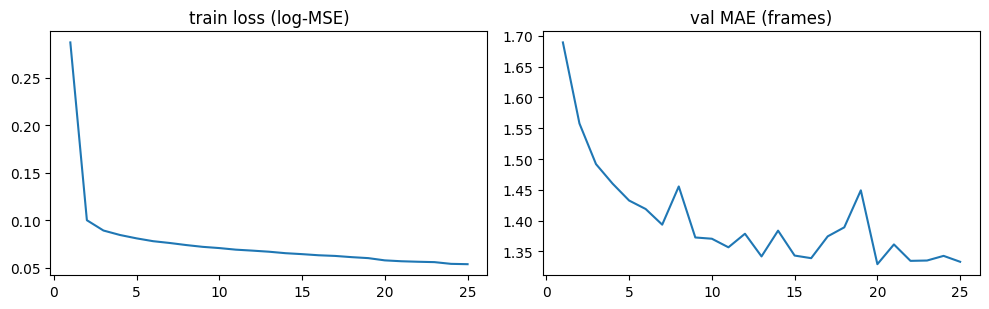

In [7]:
import matplotlib.pyplot as plt
h = pd.DataFrame(hist); fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title('train loss (log-MSE)'); ax[1].plot(h.epoch, h.val_mae_frames); ax[1].set_title('val MAE (frames)')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, '07_learning_curve.png'), dpi=150); plt.show()

## Step 4: Final scores and saved predictions (same format as notebook 06)

In [8]:
outs = []
for s in ('val', 'test'):
    rows, y, p = run_eval(s); outs.append(pd.DataFrame({'row_id': rows, 'split': s, 'y_true': y, 'y_pred': p}))
pr = pd.concat(outs); pr.to_csv(os.path.join(RESULTS, 'preds_bilstm.csv'), index=False)
sv, st_ = summarize(*[pr[pr.split == 'val'][c] for c in ('y_true', 'y_pred')]), summarize(*[pr[pr.split == 'test'][c] for c in ('y_true', 'y_pred')])
row = {'model': 'bilstm', **{f'val_{k}': v for k, v in sv.items() if k in ('mae_frames', 'mae_ms', 'rmse_frames', 'r2')},
       **{f'test_{k}': v for k, v in st_.items() if k in ('mae_frames', 'mae_ms', 'rmse_frames', 'r2')}}
json.dump({**row, 'config': CFG, 'epochs_run': len(hist)}, open(os.path.join(RESULTS, '07_nn_scores.json'), 'w'), indent=1)
sc = os.path.join(RESULTS, '06_model_scores.csv')
table = pd.concat([pd.read_csv(sc), pd.DataFrame([row])]).drop_duplicates('model', keep='last') if os.path.exists(sc) else pd.DataFrame([row])
table.to_csv(os.path.join(RESULTS, '07_all_scores.csv'), index=False); table.round(3)

,model,val_mae_frames,val_mae_ms,val_rmse_frames,val_r2,test_mae_frames,test_mae_ms,test_rmse_frames,test_r2,alpha,lr,iters
0,global_mean,3.149,36.555,4.137,-0.000,3.138,36.436,4.112,-0.000,NaN,NaN,NaN
1,phone_mean(median),2.415,28.044,3.533,0.271,2.400,27.869,3.515,0.269,NaN,NaN,NaN
2,phone_stress_pause_backoff,2.238,25.988,3.163,0.416,2.220,25.778,3.122,0.424,NaN,NaN,NaN
3,ridge,2.021,23.466,2.891,0.512,2.013,23.373,2.877,0.511,0.1,NaN,NaN
4,hist_gbm,1.536,17.838,2.273,0.698,1.540,17.879,2.265,0.697,NaN,0.05,400.0
0,bilstm,1.329,15.432,1.977,0.772,1.330,15.441,1.949,0.775,NaN,NaN,NaN
